# Modeling Human Activity States Using Hidden Markov Models

This notebook takes raw phone sensor recordings and turns them into a Hidden Markov Model that can tell what activity I am doing: **still**, **standing**, **walking** or **jumping**.

The steps are:

1. Load and clean the raw recordings
2. Extract time and frequency features
3. Build the HMM from scratch with numpy (Baum-Welch and Viterbi)
4. Test the model on three unseen recordings

Run every cell from top to bottom, from the project root.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.axes import Axes
from matplotlib.figure import Figure
from matplotlib.patches import Rectangle

from hmm_types import SamplingRateRow, WindowFeatures, HmmModel, ActivityMetrics, SessionAccuracy

In [2]:
RAW_FOLDER = "data/raw"
TRAIN_FOLDER = "data/cleaned/train"
TEST_FOLDER = "data/cleaned/test"
FIGURES_FOLDER = "figures"
TEST_LABELS_FILE = "data/test_labels.csv"

ACCELEROMETER_FILE = "TotalAcceleration.csv"
GYROSCOPE_FILE = "Gyroscope.csv"

ACTIVITIES = ["still", "standing", "walking", "jumping"]
TEST_SESSIONS = ["test_01", "test_02", "test_03"]
AXES = ["x", "y", "z"]
TRANSITION_LABEL = "transition"

TARGET_RATE = 100
MAX_ALLOWED_GAP = 0.1
TRIM_SECONDS = 2
CLIP_SECONDS = 10
DECIMAL_PLACES = 5

ACTIVITY_COLORS = {
    "still": "#2a78d6",
    "standing": "#eb6834",
    "walking": "#1baf7a",
    "jumping": "#eda100",
}

AXIS_COLORS = {
    "x": "#2a78d6",
    "y": "#eb6834",
    "z": "#1baf7a",
}

SIGNAL_COLOR = "#52514e"
GRID_COLOR = "#e5e5e5"
BLOCK_SHADE_ALPHA = 0.25
FIGURE_DPI = 150
EXAMPLE_CLIP_NUMBER = 5

WINDOW_SECONDS = 2
STEP_SECONDS = 1
WINDOW_SIZE = WINDOW_SECONDS * TARGET_RATE
STEP_SIZE = STEP_SECONDS * TARGET_RATE
LOG_OFFSET = 1e-6

FEATURE_NAMES = [
    "acc_mean",
    "acc_std",
    "gyro_mean",
    "sma",
    "tilt_degrees",
    "yz_correlation",
    "dominant_frequency",
    "spectral_energy",
]

LOG_FEATURES = ["acc_std", "gyro_mean", "sma", "spectral_energy"]

STATE_COUNT = len(ACTIVITIES)
RANDOM_SEED = 42
MIN_VARIANCE = 1e-3
INITIAL_VARIANCE = 1.0
CONVERGENCE_TOLERANCE = 1e-4
MAX_ITERATIONS = 200

SEQUENTIAL_COLOR_MAP = "Blues"
DIVERGING_COLOR_MAP = "RdBu_r"
HEATMAP_LABEL_BOX = {"facecolor": "white", "alpha": 0.7, "edgecolor": "none"}
EMISSION_CURVE_FEATURES = ["acc_std", "tilt_degrees"]
CURVE_X_MIN = -2.5
CURVE_X_MAX = 2.5
CURVE_POINTS = 500
TRUE_LABEL_COLOR = "#b5b4ae"
TRUE_MARKER_SIZE = 40
PREDICTED_LINE_COLOR = "#2a78d6"

In [3]:
os.makedirs(TRAIN_FOLDER, exist_ok=True)

os.makedirs(TEST_FOLDER, exist_ok=True)

os.makedirs(FIGURES_FOLDER, exist_ok=True)

plt.rcParams["axes.spines.top"] = False

plt.rcParams["axes.spines.right"] = False

plt.rcParams["axes.grid"] = True

plt.rcParams["grid.color"] = GRID_COLOR

plt.rcParams["axes.titlesize"] = 11

plt.rcParams["axes.labelsize"] = 10

plt.rcParams["lines.linewidth"] = 1.2

## 1. Data Collection

All data was recorded with the **Sensor Logger** app on one Android phone. Each recording is a folder of CSV files, one per sensor. We use two of them:

- `TotalAcceleration.csv`: accelerometer x, y, z in m/s², **including gravity**. Keeping gravity matters, because gravity tells us how the phone is oriented (flat on a table vs held in the hand).
- `Gyroscope.csv`: rotation speed around x, y, z in rad/s.

There are 7 recordings:

| Recording | Purpose |
|---|---|
| `still`, `standing`, `walking`, `jumping` | Training: one long recording per activity |
| `test_01`, `test_02`, `test_03` | Unseen test sessions: all activities in one recording, with transitions |

In [4]:
def load_sensor(recording_name: str, sensor_file: str) -> pd.DataFrame:
    path = os.path.join(RAW_FOLDER, recording_name, sensor_file)

    sensor_data = pd.read_csv(path)

    return sensor_data[["seconds_elapsed", "x", "y", "z"]]


def measure_sampling_rate(sensor_data: pd.DataFrame) -> float:
    time_steps = sensor_data["seconds_elapsed"].diff()

    median_step = time_steps.median()

    return 1 / median_step


def measure_duration(sensor_data: pd.DataFrame) -> float:
    first_time = sensor_data["seconds_elapsed"].iloc[0]

    last_time = sensor_data["seconds_elapsed"].iloc[-1]

    return last_time - first_time

In [5]:
rate_rows: list[SamplingRateRow] = []

for recording_name in ACTIVITIES + TEST_SESSIONS:
    accelerometer = load_sensor(recording_name, ACCELEROMETER_FILE)

    gyroscope = load_sensor(recording_name, GYROSCOPE_FILE)

    rate_row: SamplingRateRow = {
        "recording": recording_name,
        "duration_seconds": round(measure_duration(accelerometer), 1),
        "accelerometer_hz": round(measure_sampling_rate(accelerometer), 1),
        "gyroscope_hz": round(measure_sampling_rate(gyroscope), 1),
    }

    rate_rows.append(rate_row)

sampling_rates = pd.DataFrame(rate_rows)

sampling_rates

,recording,duration_seconds,accelerometer_hz,gyroscope_hz
0,still,575.0,52.5,105.0
1,standing,163.2,105.0,105.0
2,walking,170.8,105.0,105.0
3,jumping,141.4,105.0,105.0
4,test_01,78.7,105.0,105.0
5,test_02,78.6,105.0,105.0
6,test_03,102.0,105.0,105.0


### Sampling rate

The app was set to record every 10 ms, but the phone actually delivers a sample about every **9.5 ms (about 105 Hz)**. Android does not guarantee perfectly even timing, and the accelerometer and gyroscope do not share exact timestamps either.

The still recording shows only about 52 Hz for the accelerometer. That is not the real recording rate: the phone fell asleep part way through, which is explained and handled below.

To fix both problems, every recording is **resampled onto one fixed 100 Hz grid** (one row every 0.01 s) using linear interpolation. After this step:

- every row is exactly 0.01 s apart
- the accelerometer and gyroscope values sit on the same timestamps, so they can live in one table
- any future recording from a different phone can be harmonised the same way

100 Hz is far above what we need. Walking (about 1.6 Hz) and jumping (about 2.1 Hz) get roughly 50 samples per movement cycle, and the Nyquist limit is 50 Hz.

In [6]:
def find_usable_end(sensor_data: pd.DataFrame) -> float:
    time_steps = sensor_data["seconds_elapsed"].diff()

    big_gaps = time_steps[time_steps > MAX_ALLOWED_GAP]

    if len(big_gaps) == 0:
        return sensor_data["seconds_elapsed"].iloc[-1]

    first_gap_row = big_gaps.index[0]

    return sensor_data["seconds_elapsed"].iloc[first_gap_row - 1]


def resample_axis(sensor_data: pd.DataFrame, axis: str, new_times: np.ndarray) -> np.ndarray:
    old_times = sensor_data["seconds_elapsed"]

    old_values = sensor_data[axis]

    return np.interp(new_times, old_times, old_values)


def load_recording(recording_name: str) -> pd.DataFrame:
    accelerometer = load_sensor(recording_name, ACCELEROMETER_FILE)

    gyroscope = load_sensor(recording_name, GYROSCOPE_FILE)

    accelerometer_start = accelerometer["seconds_elapsed"].iloc[0]

    gyroscope_start = gyroscope["seconds_elapsed"].iloc[0]

    start_time = max(accelerometer_start, gyroscope_start)

    end_time = min(find_usable_end(accelerometer), find_usable_end(gyroscope))

    time_step = 1 / TARGET_RATE

    new_times = np.arange(start_time, end_time, time_step)

    recording = pd.DataFrame({"time": new_times})

    for axis in AXES:
        recording["acc_" + axis] = resample_axis(accelerometer, axis, new_times)

    for axis in AXES:
        recording["gyro_" + axis] = resample_axis(gyroscope, axis, new_times)

    return recording

`find_usable_end` exists because of the **still** recording. The phone was left on the table for 9.6 minutes, and after about 182 s Android put it to sleep: the gyroscope stopped for over 6 minutes and the accelerometer dropped to half speed. Interpolating across that gap would invent fake data, so each recording is cut at its first gap longer than 0.1 s. For still, that leaves about 3 minutes of clean data, which is still more than any other activity.

## 2. Cleaning the Training Data

Each training recording is one long session of a single activity. To turn it into clean, well-labelled files:

1. **Trim 2 seconds from the start and the end.** Pressing start and stop on the phone shakes it, and that shake is not part of the activity.
2. **Cut the rest into 10 second clips**, matching the 5 to 10 s recording length in the brief.
3. **Keep the same number of clips for every activity**, so no activity outweighs the others when the model is trained.

In [7]:
def cut_into_clips(recording: pd.DataFrame) -> list[pd.DataFrame]:
    first_time = recording["time"].iloc[0] + TRIM_SECONDS

    last_time = recording["time"].iloc[-1] - TRIM_SECONDS

    clips: list[pd.DataFrame] = []

    clip_start = first_time

    while clip_start + CLIP_SECONDS <= last_time:
        clip_end = clip_start + CLIP_SECONDS

        after_start = recording["time"] >= clip_start

        before_end = recording["time"] < clip_end

        clip = recording[after_start & before_end].copy()

        clip["time"] = clip["time"] - clip_start

        clips.append(clip)

        clip_start = clip_end

    return clips


def save_training_clips(activity: str, clips: list[pd.DataFrame]) -> None:
    for clip_number, clip in enumerate(clips, start=1):
        labelled_clip = clip.copy()

        labelled_clip["activity"] = activity

        file_name = f"{activity}_{clip_number:02d}.csv"

        file_path = os.path.join(TRAIN_FOLDER, file_name)

        labelled_clip.round(DECIMAL_PLACES).to_csv(file_path, index=False)

In [8]:
all_clips: dict[str, list[pd.DataFrame]] = {}

for activity in ACTIVITIES:
    recording = load_recording(activity)

    all_clips[activity] = cut_into_clips(recording)

    print(f"{activity}: {len(all_clips[activity])} clips")

clip_counts = [len(clips) for clips in all_clips.values()]

clips_per_activity = min(clip_counts)

print(f"Keeping {clips_per_activity} clips per activity")

still: 17 clips
standing: 15 clips


walking: 16 clips
jumping: 13 clips
Keeping 13 clips per activity


In [9]:
for activity in ACTIVITIES:
    kept_clips = all_clips[activity][:clips_per_activity]

    save_training_clips(activity, kept_clips)

train_files = sorted(os.listdir(TRAIN_FOLDER))

seconds_per_activity = clips_per_activity * CLIP_SECONDS

print(f"Saved {len(train_files)} training files")

print(f"Each activity has {seconds_per_activity} seconds of data")

Saved 52 training files
Each activity has 130 seconds of data


## 3. Labelling the Test Sessions

Each test session is one continuous recording with all four activities in it. I followed a timer (15 s per activity, 5 s to move into the next one), and adjusted the blocks where my timing drifted. The true labels live in `data/test_labels.csv`.

Anything outside a labelled block is a **transition** (for example putting the phone down on the table). The model still decodes those seconds, but they are **not scored**, because they are not any one activity.

In [10]:
test_labels = pd.read_csv(TEST_LABELS_FILE)

test_labels

,session,activity,start_seconds,end_seconds,surface
0,test_01,still,0,15,table
1,test_01,standing,20,35,floor
2,test_01,walking,40,55,floor
3,test_01,jumping,60,75,floor
4,test_02,walking,0,15,floor
5,test_02,standing,20,35,carpet
6,test_02,jumping,40,55,carpet
7,test_02,still,66,78,table
8,test_03,standing,0,15,carpet
9,test_03,jumping,22,35,floor


In [11]:
def label_test_session(recording: pd.DataFrame, session_name: str) -> pd.DataFrame:
    recording["activity"] = TRANSITION_LABEL

    session_blocks = test_labels[test_labels["session"] == session_name]

    for _, block in session_blocks.iterrows():
        after_start = recording["time"] >= block["start_seconds"]

        before_end = recording["time"] < block["end_seconds"]

        recording.loc[after_start & before_end, "activity"] = block["activity"]

    return recording


def save_test_session(session: pd.DataFrame, session_name: str) -> None:
    file_path = os.path.join(TEST_FOLDER, f"{session_name}.csv")

    session.round(DECIMAL_PLACES).to_csv(file_path, index=False)

In [12]:
for session_name in TEST_SESSIONS:
    recording = load_recording(session_name)

    labelled_session = label_test_session(recording, session_name)

    save_test_session(labelled_session, session_name)

    session_length = labelled_session["time"].iloc[-1]

    print(f"{session_name}: {session_length:.1f} seconds")

    print(labelled_session["activity"].value_counts().to_string(), "\n")

test_01: 78.9 seconds
activity
transition    1893
standing      1500
walking       1500
jumping       1500
still         1468 

test_02: 78.8 seconds
activity
transition    2184
standing      1500
jumping       1500
walking       1470
still         1200 



test_03: 102.2 seconds
activity
transition    3222
standing      2667
walking       1500
still         1500
jumping       1300 



## 4. Visualising the Raw Data

One 10 second clip from each activity. The activities already look very different:

- **still**: flat lines, gravity sits on the z axis (about 9.8 m/s²) because the phone lies flat
- **standing**: almost flat, with small wobbles from my hand
- **walking**: a regular rhythm, roughly 1.6 steps per second
- **jumping**: very large spikes on landing, up to about 5 g

In [13]:
def load_training_clip(activity: str, clip_number: int) -> pd.DataFrame:
    file_name = f"{activity}_{clip_number:02d}.csv"

    file_path = os.path.join(TRAIN_FOLDER, file_name)

    return pd.read_csv(file_path)


def plot_sensor_axes(clip: pd.DataFrame, sensor_prefix: str, axis_plot: Axes) -> None:
    for axis in AXES:
        column = sensor_prefix + axis

        axis_plot.plot(clip["time"], clip[column], color=AXIS_COLORS[axis], label=axis)


def plot_example_clips(clip_number: int) -> Figure:
    figure, axes = plt.subplots(len(ACTIVITIES), 2, figsize=(12, 10), sharex=True)

    for row, activity in enumerate(ACTIVITIES):
        clip = load_training_clip(activity, clip_number)

        accelerometer_plot = axes[row, 0]

        gyroscope_plot = axes[row, 1]

        plot_sensor_axes(clip, "acc_", accelerometer_plot)

        plot_sensor_axes(clip, "gyro_", gyroscope_plot)

        accelerometer_plot.set_title(f"{activity.title()}: accelerometer")

        gyroscope_plot.set_title(f"{activity.title()}: gyroscope")

        accelerometer_plot.set_ylabel("m/s²")

        gyroscope_plot.set_ylabel("rad/s")

    axes[0, 0].legend(loc="upper right", ncol=3)

    axes[-1, 0].set_xlabel("Time (s)")

    axes[-1, 1].set_xlabel("Time (s)")

    figure.tight_layout()

    return figure

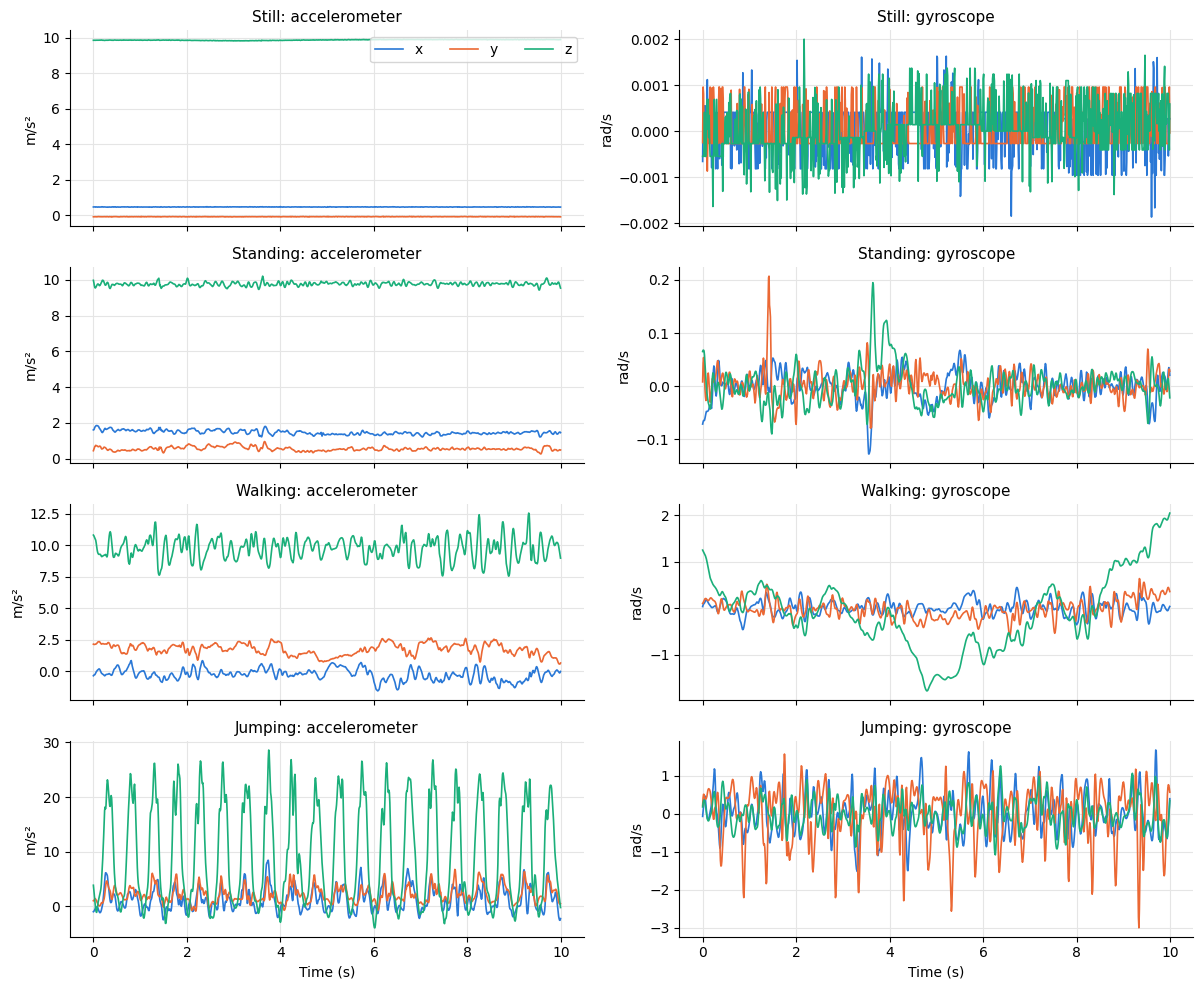

In [14]:
example_figure = plot_example_clips(EXAMPLE_CLIP_NUMBER)

example_figure.savefig(os.path.join(FIGURES_FOLDER, "raw_example_clips.png"), dpi=FIGURE_DPI)

plt.show()

The test sessions show the activities one after another. The shaded blocks are the true labels, and the white gaps are the unscored transitions.

In [15]:
def calculate_sensor_size(recording: pd.DataFrame, sensor_prefix: str) -> np.ndarray:
    x_values = recording[sensor_prefix + "x"].to_numpy()

    y_values = recording[sensor_prefix + "y"].to_numpy()

    z_values = recording[sensor_prefix + "z"].to_numpy()

    squared_sum = x_values ** 2 + y_values ** 2 + z_values ** 2

    return np.sqrt(squared_sum)


def plot_test_session(session_name: str, axis_plot: Axes) -> None:
    file_path = os.path.join(TEST_FOLDER, f"{session_name}.csv")

    session = pd.read_csv(file_path)

    acceleration_size = calculate_sensor_size(session, "acc_")

    axis_plot.plot(session["time"], acceleration_size, color=SIGNAL_COLOR, linewidth=0.8)

    session_blocks = test_labels[test_labels["session"] == session_name]

    for _, block in session_blocks.iterrows():
        color = ACTIVITY_COLORS[block["activity"]]

        axis_plot.axvspan(block["start_seconds"], block["end_seconds"], color=color, alpha=BLOCK_SHADE_ALPHA)

    axis_plot.set_title(session_name)

    axis_plot.set_ylabel("|acceleration| (m/s²)")


def make_activity_legend_patches() -> list[Rectangle]:
    legend_patches: list[Rectangle] = []

    for activity in ACTIVITIES:
        patch = Rectangle((0, 0), 1, 1, color=ACTIVITY_COLORS[activity], alpha=BLOCK_SHADE_ALPHA)

        legend_patches.append(patch)

    return legend_patches

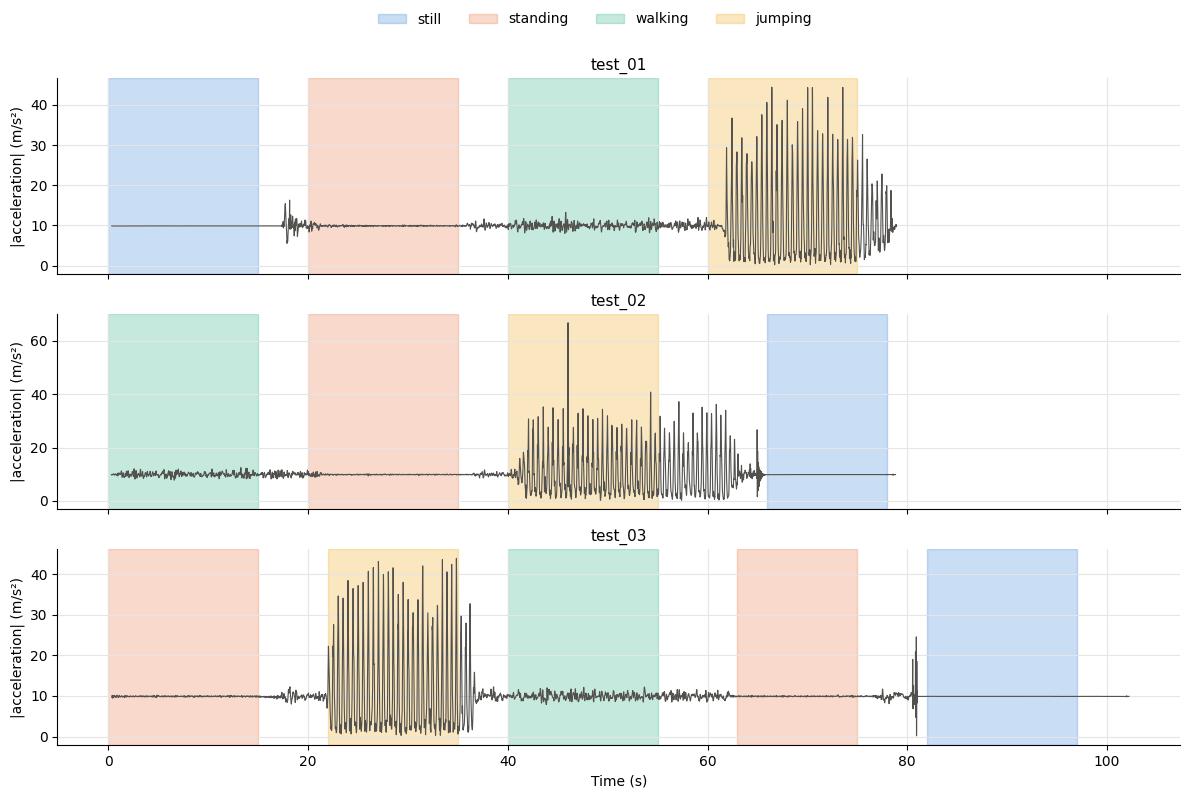

In [16]:
test_figure, test_axes = plt.subplots(len(TEST_SESSIONS), 1, figsize=(12, 8), sharex=True)

for row, session_name in enumerate(TEST_SESSIONS):
    plot_test_session(session_name, test_axes[row])

legend_patches = make_activity_legend_patches()

test_figure.legend(legend_patches, ACTIVITIES, loc="upper center", ncol=len(ACTIVITIES), frameon=False)

test_axes[-1].set_xlabel("Time (s)")

test_figure.tight_layout(rect=(0, 0, 1, 0.95))

test_figure.savefig(os.path.join(FIGURES_FOLDER, "test_sessions_raw.png"), dpi=FIGURE_DPI)

plt.show()

## 5. Feature Extraction

### Windowing

The HMM does not look at raw samples. It looks at one **feature vector per window** of time.

- **Window length: 2 seconds (200 samples at 100 Hz).** Walking repeats about 1.6 times per second and jumping about 2.1 times per second, so a 2 s window always holds 3 to 4 full steps or jumps. That is enough for the FFT to find the rhythm. A 2 s window also gives the FFT a frequency resolution of 1 / 2 s = 0.5 Hz, fine enough to separate walking from jumping.
- **Step: 1 second (100 samples), so windows overlap by 50%.** The HMM gets one observation every second, which matches how fast I can realistically switch activities.

Each 10 s training clip gives 9 windows. In the test sessions, a window gets an activity label only if every sample in it belongs to the same labelled block. Windows that touch a transition are labelled `transition` and are not scored.

In [17]:
def cut_into_windows(recording: pd.DataFrame) -> list[pd.DataFrame]:
    windows: list[pd.DataFrame] = []

    last_start = len(recording) - WINDOW_SIZE

    for window_start in range(0, last_start + 1, STEP_SIZE):
        window_end = window_start + WINDOW_SIZE

        window = recording.iloc[window_start:window_end]

        windows.append(window)

    return windows


def find_window_label(window: pd.DataFrame) -> str:
    labels_in_window = window["activity"].unique()

    if len(labels_in_window) == 1:
        return labels_in_window[0]

    return TRANSITION_LABEL

### Features

Eight features are computed for every window. Six are time-domain and two come from the FFT.

| Feature | Domain | What it measures | Why it helps |
|---|---|---|---|
| `acc_mean` | Time | Average size of the acceleration | About 9.8 m/s² (gravity) when calm, higher when jumping because landings push far above gravity |
| `acc_std` | Time | How much the acceleration size moves around | The strongest separator: tiny for still, small for standing, medium for walking, huge for jumping |
| `gyro_mean` | Time | Average rotation speed | Still has none, standing has a little hand wobble, walking and jumping twist the phone a lot |
| `sma` | Time | Signal magnitude area: total movement across x, y and z, with gravity removed | Captures movement in every direction, not just along the total size |
| `tilt_degrees` | Time | Angle between gravity and the phone's z axis | A phone flat on a table sits at a different angle than one held in a hand. Key for still vs standing |
| `yz_correlation` | Time | Correlation between the y and z accelerometer axes | Walking and jumping move the axes together in a pattern, still and standing are just noise |
| `dominant_frequency` | Frequency (FFT) | The strongest rhythm in the window | Exactly 2.0 Hz in every jumping window. Walking lands either on its step rhythm (about 1.5 Hz) or on 4 to 5 Hz from sharp heel strikes. Random for still and standing |
| `spectral_energy` | Frequency (FFT) | Total energy across all frequencies | Grows hugely from still to jumping, a second view of how intense the movement is |

In [18]:
def calculate_sma(window: pd.DataFrame) -> float:
    total_movement = 0.0

    for axis in AXES:
        values = window["acc_" + axis].to_numpy()

        centred_values = values - values.mean()

        total_movement = total_movement + np.abs(centred_values).mean()

    return total_movement


def calculate_tilt_degrees(window: pd.DataFrame) -> float:
    mean_x = window["acc_x"].mean()

    mean_y = window["acc_y"].mean()

    mean_z = window["acc_z"].mean()

    gravity_size = np.sqrt(mean_x ** 2 + mean_y ** 2 + mean_z ** 2)

    tilt_radians = np.arccos(mean_z / gravity_size)

    return float(np.degrees(tilt_radians))


def calculate_yz_correlation(window: pd.DataFrame) -> float:
    y_values = window["acc_y"].to_numpy()

    z_values = window["acc_z"].to_numpy()

    correlation_matrix = np.corrcoef(y_values, z_values)

    return float(correlation_matrix[0, 1])

In [19]:
def calculate_fft_magnitudes(signal: np.ndarray) -> np.ndarray:
    centred_signal = signal - signal.mean()

    fft_values = np.fft.rfft(centred_signal)

    return np.abs(fft_values)


def calculate_dominant_frequency(signal: np.ndarray) -> float:
    magnitudes = calculate_fft_magnitudes(signal)

    frequencies = np.fft.rfftfreq(len(signal), d=1 / TARGET_RATE)

    magnitudes_without_zero = magnitudes[1:]

    strongest_bin = np.argmax(magnitudes_without_zero) + 1

    return float(frequencies[strongest_bin])


def calculate_spectral_energy(signal: np.ndarray) -> float:
    magnitudes = calculate_fft_magnitudes(signal)

    total_energy = np.sum(magnitudes ** 2)

    return float(total_energy / len(signal))

The FFT turns a window of signal into a list of frequencies and how strong each one is. Before the FFT the average is subtracted (centring), otherwise gravity shows up as a giant 0 Hz spike that hides everything else. For the same reason the 0 Hz bin is skipped when looking for the dominant frequency.

**What the dominant frequency actually found:** jumping came out at exactly 2.0 Hz in all 117 training windows. Walking was split: 29 windows found the step rhythm at 1.5 Hz, but most found 4 to 5 Hz instead. Each heel strike is a short, sharp bump, and sharp bumps create harmonics (multiples of the step rate) that can be stronger than the step rate itself. So this feature is very reliable for jumping and noisier for walking, which is why it is combined with the time-domain features instead of being used alone.

In [20]:
def extract_window_features(window: pd.DataFrame) -> WindowFeatures:
    acceleration_size = calculate_sensor_size(window, "acc_")

    rotation_size = calculate_sensor_size(window, "gyro_")

    features: WindowFeatures = {
        "acc_mean": float(acceleration_size.mean()),
        "acc_std": float(acceleration_size.std()),
        "gyro_mean": float(rotation_size.mean()),
        "sma": calculate_sma(window),
        "tilt_degrees": calculate_tilt_degrees(window),
        "yz_correlation": calculate_yz_correlation(window),
        "dominant_frequency": calculate_dominant_frequency(acceleration_size),
        "spectral_energy": calculate_spectral_energy(acceleration_size),
    }

    return features


def build_feature_table(recording: pd.DataFrame) -> pd.DataFrame:
    windows = cut_into_windows(recording)

    feature_rows: list[WindowFeatures] = []

    window_labels: list[str] = []

    window_start_times: list[float] = []

    for window in windows:
        feature_rows.append(extract_window_features(window))

        window_labels.append(find_window_label(window))

        window_start_times.append(window["time"].iloc[0])

    feature_table = pd.DataFrame(feature_rows)

    feature_table["start_time"] = window_start_times

    feature_table["activity"] = window_labels

    return feature_table

In [21]:
training_tables: list[pd.DataFrame] = []

for file_name in train_files:
    clip = pd.read_csv(os.path.join(TRAIN_FOLDER, file_name))

    clip_features = build_feature_table(clip)

    clip_features["clip"] = file_name

    training_tables.append(clip_features)

train_features = pd.concat(training_tables, ignore_index=True)

print(f"Training windows: {len(train_features)}")

print(train_features["activity"].value_counts().to_string())

Training windows: 468
activity
jumping     117
standing    117
still       117
walking     117


In [22]:
test_features: dict[str, pd.DataFrame] = {}

for session_name in TEST_SESSIONS:
    session = pd.read_csv(os.path.join(TEST_FOLDER, f"{session_name}.csv"))

    test_features[session_name] = build_feature_table(session)

    window_count = len(test_features[session_name])

    scored_count = (test_features[session_name]["activity"] != TRANSITION_LABEL).sum()

    print(f"{session_name}: {window_count} windows, {scored_count} scored")

test_01: 77 windows, 52 scored


test_02: 77 windows, 49 scored


test_03: 100 windows, 60 scored


In [23]:
train_features.groupby("activity")[FEATURE_NAMES].mean().loc[ACTIVITIES].round(3)

,acc_mean,acc_std,gyro_mean,sma,tilt_degrees,yz_correlation,dominant_frequency,spectral_energy
activity,,,,,,,,
still,9.877,0.008,0.001,0.016,2.730,-0.013,4.329,0.009
standing,9.893,0.073,0.030,0.157,9.072,0.088,6.325,0.616
walking,9.920,0.881,0.740,1.418,9.919,-0.059,3.517,81.182
jumping,10.837,8.819,1.009,11.770,16.043,0.649,2.000,7837.314


### Normalisation

The features live on very different scales. `tilt_degrees` is in degrees, `dominant_frequency` is in Hz, and `spectral_energy` goes from about 0.0001 for still to over 10,000 for jumping. If we fed these straight into the HMM, the features with the biggest numbers would drown out the rest.

Two steps fix this:

1. **Log scale** for the four features that grow by several orders of magnitude (`acc_std`, `gyro_mean`, `sma`, `spectral_energy`). Without it, still, standing and walking would all be squashed together near zero next to jumping. The log spreads them out and makes each activity look more like a bell curve, which is exactly what the Gaussian emissions in the HMM assume.
2. **Z-score** every feature: subtract the mean and divide by the standard deviation, so every feature ends up centred on 0 with a spread of 1. The mean and standard deviation come **from the training windows only** and are then reused on the test windows. Calculating them on the test data would leak information about the unseen sessions into the model.

Z-score was picked over min-max scaling because min-max depends on the single biggest and smallest values, and a single hard landing (like the 72.8 m/s² spike in test_02) would squash every other value.

In [24]:
def apply_log_scale(feature_table: pd.DataFrame) -> pd.DataFrame:
    scaled_table = feature_table.copy()

    for feature_name in LOG_FEATURES:
        scaled_table[feature_name] = np.log10(scaled_table[feature_name] + LOG_OFFSET)

    return scaled_table


def apply_z_score(feature_table: pd.DataFrame, means: pd.Series, stds: pd.Series) -> pd.DataFrame:
    normalised_table = feature_table.copy()

    normalised_table[FEATURE_NAMES] = (feature_table[FEATURE_NAMES] - means) / stds

    return normalised_table

In [25]:
train_log_scaled = apply_log_scale(train_features)

training_means = train_log_scaled[FEATURE_NAMES].mean()

training_stds = train_log_scaled[FEATURE_NAMES].std()

train_normalised = apply_z_score(train_log_scaled, training_means, training_stds)

test_normalised: dict[str, pd.DataFrame] = {}

for session_name in TEST_SESSIONS:
    session_log_scaled = apply_log_scale(test_features[session_name])

    test_normalised[session_name] = apply_z_score(session_log_scaled, training_means, training_stds)

train_normalised[FEATURE_NAMES].describe().loc[["mean", "std"]].round(3)

,acc_mean,acc_std,gyro_mean,sma,tilt_degrees,yz_correlation,dominant_frequency,spectral_energy
mean,0.0,-0.0,0.0,0.0,-0.0,-0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


### How well do the features separate the activities?

Each box shows the spread of one normalised feature for one activity. Features where the boxes do not overlap are the ones doing the most work.

In [26]:
def plot_feature_boxes(feature_table: pd.DataFrame) -> Figure:
    figure, axes = plt.subplots(2, 4, figsize=(14, 7))

    flat_axes = axes.flatten()

    for plot_number, feature_name in enumerate(FEATURE_NAMES):
        feature_plot = flat_axes[plot_number]

        values_per_activity: list[np.ndarray] = []

        for activity in ACTIVITIES:
            activity_rows = feature_table[feature_table["activity"] == activity]

            values_per_activity.append(activity_rows[feature_name].to_numpy())

        boxes = feature_plot.boxplot(values_per_activity, patch_artist=True, showfliers=False)

        for box, activity in zip(boxes["boxes"], ACTIVITIES):
            box.set_facecolor(ACTIVITY_COLORS[activity])

        feature_plot.set_xticks(range(1, len(ACTIVITIES) + 1))

        feature_plot.set_xticklabels(ACTIVITIES, rotation=30)

        feature_plot.set_title(feature_name)

    figure.tight_layout()

    return figure

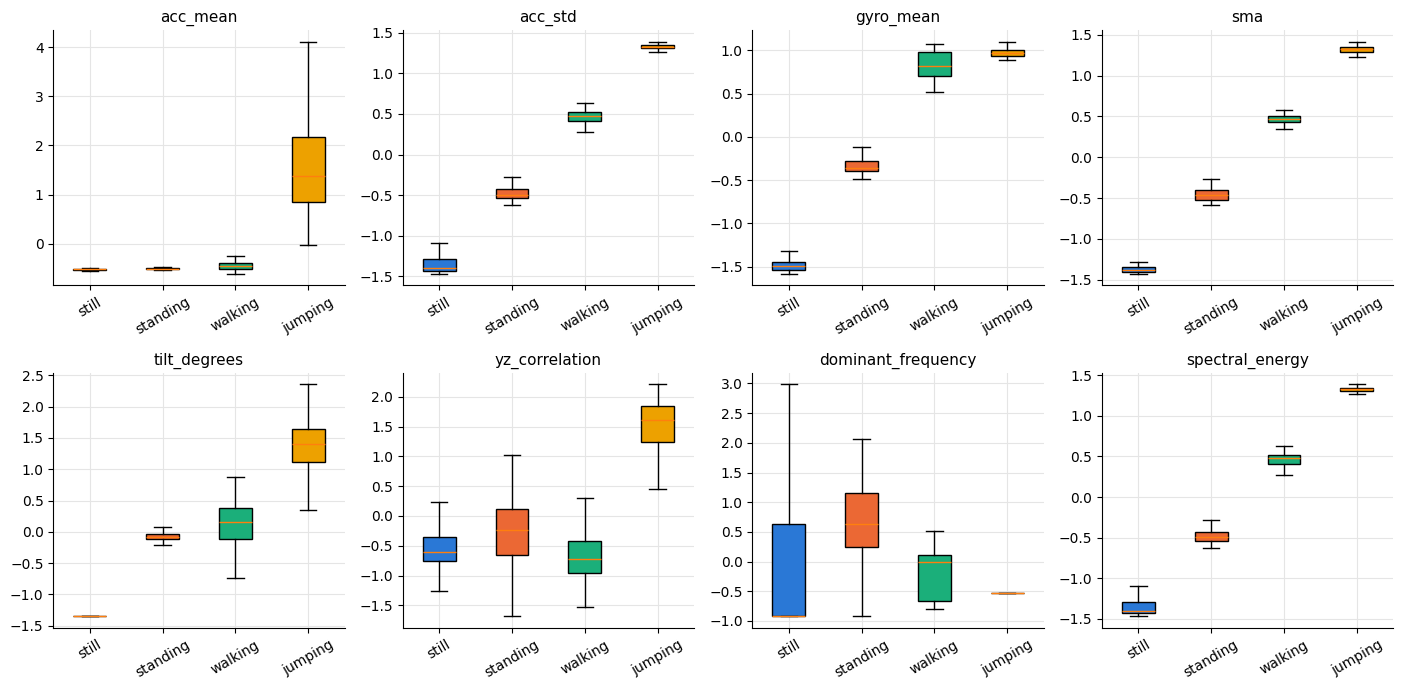

In [27]:
feature_figure = plot_feature_boxes(train_normalised)

feature_figure.savefig(os.path.join(FIGURES_FOLDER, "feature_boxplots.png"), dpi=FIGURE_DPI)

plt.show()

## 6. HMM Setup

| Element | In this project |
|---|---|
| **Hidden states (Z)** | The 4 activities: still, standing, walking, jumping. We never see them directly, only their effect on the sensors |
| **Observations (X)** | One 8-number feature vector per 2 s window (section 5), one every second |
| **Transition probabilities (A)** | A 4 x 4 table: the chance of moving from one activity to another from one second to the next |
| **Emission probabilities (B)** | For each activity, a Gaussian (bell curve) per feature: a mean and a variance. They answer "if I am walking, how likely is this feature vector?" |
| **Initial probabilities (π)** | The chance of starting in each activity. Set to 1/4 each, because a session could start with any activity |

The emissions are **Gaussian** because the features are continuous numbers, not categories. Each feature gets its own bell curve per activity (a "diagonal" Gaussian, so features are treated as independent). This keeps the model small: 4 activities x 8 features x 2 numbers (mean and variance).

### Which algorithms and why

- **Baum-Welch** trains the model. It is an Expectation-Maximisation algorithm: it repeatedly asks "given the current model, which activity was most likely at each second?" (forward-backward), then re-estimates A and B from those answers. It improves the log-likelihood every round, so we stop when the improvement drops below a small tolerance.
- **Viterbi** decodes the test sessions. It finds the single most likely **sequence** of activities, not just the best activity for each window on its own. That matters for the metrics: a window that looks a bit like standing in the middle of a long still block will be pulled back to still by the transition probabilities, which cuts down on isolated mistakes. Fewer flickering errors means higher sensitivity and specificity per activity.
- **Forward-backward** is used inside Baum-Welch to compute how likely each activity is at each second, and the forward pass also gives the log-likelihood used for the convergence check.

### Building the training sequence

Each training clip contains only one activity, so on its own the training data has no transitions to learn from. To give the model a sequence to learn from, the 52 clips are **shuffled into a random order** (with a fixed seed, so the result is the same every run) and joined into one long sequence of 468 windows.

The learned transition matrix will reflect this design: long stays inside each activity (9 windows per clip) and switches between any two activities at random. Real life is different, for example I never go from jumping straight to lying the phone still. This is discussed in the analysis.

In [28]:
def build_training_sequence(feature_table: pd.DataFrame) -> pd.DataFrame:
    clip_names = feature_table["clip"].unique()

    random_generator = np.random.default_rng(RANDOM_SEED)

    shuffled_clip_names = random_generator.permutation(clip_names)

    ordered_tables: list[pd.DataFrame] = []

    for clip_name in shuffled_clip_names:
        clip_rows = feature_table[feature_table["clip"] == clip_name]

        ordered_tables.append(clip_rows)

    return pd.concat(ordered_tables, ignore_index=True)


def convert_activities_to_states(activities: pd.Series) -> np.ndarray:
    state_numbers = [ACTIVITIES.index(activity) for activity in activities]

    return np.array(state_numbers)


def convert_states_to_activities(states: np.ndarray) -> list[str]:
    return [ACTIVITIES[state] for state in states]

In [29]:
training_sequence = build_training_sequence(train_normalised)

training_observations = training_sequence[FEATURE_NAMES].to_numpy()

training_states = convert_activities_to_states(training_sequence["activity"])

print(f"Training sequence: {len(training_observations)} windows x {training_observations.shape[1]} features")

print("First 20 activities:", convert_states_to_activities(training_states[:20]))

Training sequence: 468 windows x 8 features
First 20 activities: ['still', 'still', 'still', 'still', 'still', 'still', 'still', 'still', 'still', 'jumping', 'jumping', 'jumping', 'jumping', 'jumping', 'jumping', 'jumping', 'jumping', 'jumping', 'walking', 'walking']


## 7. HMM Implementation (from scratch with numpy)

### Starting point

Baum-Welch needs a starting model. It is given a deliberately **vague** one, so that it has to learn the details itself:

- **means**: the average of each feature for each activity, taken from the labelled windows. This anchors state 0 = still, state 1 = standing, and so on, so we know which hidden state is which activity after training.
- **variances**: 1.0 for everything (the spread of the whole z-scored data set). Baum-Welch has to work out how tight or wide each activity really is.
- **transition matrix**: 0.25 everywhere, meaning "any activity is equally likely to follow any other". Baum-Welch has to discover that activities tend to last.
- **start probabilities**: 1/4 each

An earlier version started Baum-Welch from the exact labelled statistics (counted transitions and real variances). Because the four activities barely overlap, that starting point was already the answer, and Baum-Welch stopped after 2 rounds with nothing to improve. Starting vague shows the algorithm actually learning. As a check, the transitions it learns are compared with the ones counted directly from the labels.

Variances have a floor (`MIN_VARIANCE`). Without it, a feature that barely moves for one activity (like tilt for still, where the phone lies perfectly flat) gets a near zero variance, and any tiny difference in a new recording becomes "impossible" for that activity.

In [30]:
def count_transitions(states: np.ndarray) -> np.ndarray:
    transition_counts = np.zeros((STATE_COUNT, STATE_COUNT))

    for time in range(len(states) - 1):
        current_state = states[time]

        next_state = states[time + 1]

        transition_counts[current_state, next_state] = transition_counts[current_state, next_state] + 1

    row_totals = transition_counts.sum(axis=1, keepdims=True)

    return transition_counts / row_totals


def build_initial_model(observations: np.ndarray, states: np.ndarray) -> HmmModel:
    feature_count = observations.shape[1]

    means = np.zeros((STATE_COUNT, feature_count))

    for state in range(STATE_COUNT):
        state_observations = observations[states == state]

        means[state] = state_observations.mean(axis=0)

    variances = np.full((STATE_COUNT, feature_count), INITIAL_VARIANCE)

    start_probabilities = np.full(STATE_COUNT, 1 / STATE_COUNT)

    transition_matrix = np.full((STATE_COUNT, STATE_COUNT), 1 / STATE_COUNT)

    model: HmmModel = {
        "start_probabilities": start_probabilities,
        "transition_matrix": transition_matrix,
        "means": means,
        "variances": variances,
    }

    return model

### Emission probabilities

For each window and each activity, the emission is the Gaussian probability of the window's features, multiplied across the 8 features. Multiplying 8 small numbers gives a tiny number, so the work is done with **logs** (adding log probabilities instead of multiplying probabilities).

For the forward and backward passes we need real probabilities again. Each row is shifted so its biggest value becomes 1 before converting back with `exp`. The shift is remembered and added back into the log-likelihood, so nothing is lost.

In [31]:
def calculate_log_emissions(observations: np.ndarray, model: HmmModel) -> np.ndarray:
    log_emissions = np.zeros((len(observations), STATE_COUNT))

    for state in range(STATE_COUNT):
        mean = model["means"][state]

        variance = model["variances"][state]

        squared_distance = (observations - mean) ** 2 / variance

        log_normaliser = np.log(2 * np.pi * variance)

        log_densities = -0.5 * (squared_distance + log_normaliser)

        log_emissions[:, state] = log_densities.sum(axis=1)

    return log_emissions


def shift_to_probabilities(log_emissions: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    row_maximums = log_emissions.max(axis=1)

    shifted_log_emissions = log_emissions - row_maximums.reshape(-1, 1)

    return np.exp(shifted_log_emissions), row_maximums

### Forward and backward passes

- **Forward (alpha)**: walking through time from the start, "how likely is each activity right now, given everything seen so far?"
- **Backward (beta)**: walking back from the end, "how well does each activity right now explain everything that comes after?"

Each step is rescaled so the numbers add up to 1 (otherwise they shrink towards zero over hundreds of windows). The scale factors are kept, because adding up their logs gives the log-likelihood of the whole sequence.

In [32]:
def run_forward(emissions: np.ndarray, model: HmmModel) -> tuple[np.ndarray, np.ndarray]:
    observation_count = len(emissions)

    alpha = np.zeros((observation_count, STATE_COUNT))

    scales = np.zeros(observation_count)

    first_alpha = model["start_probabilities"] * emissions[0]

    scales[0] = first_alpha.sum()

    alpha[0] = first_alpha / scales[0]

    for time in range(1, observation_count):
        predicted = alpha[time - 1] @ model["transition_matrix"]

        new_alpha = predicted * emissions[time]

        scales[time] = new_alpha.sum()

        alpha[time] = new_alpha / scales[time]

    return alpha, scales


def run_backward(emissions: np.ndarray, scales: np.ndarray, model: HmmModel) -> np.ndarray:
    observation_count = len(emissions)

    beta = np.ones((observation_count, STATE_COUNT))

    for time in range(observation_count - 2, -1, -1):
        next_evidence = emissions[time + 1] * beta[time + 1]

        beta[time] = (model["transition_matrix"] @ next_evidence) / scales[time + 1]

    return beta


def calculate_log_likelihood(scales: np.ndarray, row_maximums: np.ndarray) -> float:
    return float(np.log(scales).sum() + row_maximums.sum())

### Baum-Welch

Each round has two steps:

1. **Expectation**: use forward and backward to get `gamma` (how likely each activity is at each second) and the expected number of moves between each pair of activities.
2. **Maximisation**: re-estimate the transition matrix, means and variances from those expectations.

**Convergence check:** after each round the log-likelihood is compared with the previous round. Once it improves by less than `CONVERGENCE_TOLERANCE`, training stops. `MAX_ITERATIONS` is only a safety limit in case it never settles.

The start probabilities are not re-estimated. With one training sequence, Baum-Welch would learn them from a single starting window and decide that every session must start with that one activity.

In [33]:
def calculate_state_posteriors(alpha: np.ndarray, beta: np.ndarray) -> np.ndarray:
    unnormalised = alpha * beta

    row_totals = unnormalised.sum(axis=1, keepdims=True)

    return unnormalised / row_totals


def sum_expected_transitions(alpha: np.ndarray, beta: np.ndarray, emissions: np.ndarray, scales: np.ndarray, model: HmmModel) -> np.ndarray:
    expected_transitions = np.zeros((STATE_COUNT, STATE_COUNT))

    for time in range(len(emissions) - 1):
        next_evidence = emissions[time + 1] * beta[time + 1]

        pair_weights = np.outer(alpha[time], next_evidence)

        transition_posterior = pair_weights * model["transition_matrix"] / scales[time + 1]

        expected_transitions = expected_transitions + transition_posterior

    return expected_transitions


def update_model(observations: np.ndarray, gamma: np.ndarray, expected_transitions: np.ndarray, model: HmmModel) -> HmmModel:
    row_totals = expected_transitions.sum(axis=1, keepdims=True)

    new_transition_matrix = expected_transitions / row_totals

    new_means = np.zeros_like(model["means"])

    new_variances = np.zeros_like(model["variances"])

    for state in range(STATE_COUNT):
        weights = gamma[:, state]

        weight_total = weights.sum()

        new_means[state] = (weights @ observations) / weight_total

        squared_differences = (observations - new_means[state]) ** 2

        new_variances[state] = (weights @ squared_differences) / weight_total

    new_variances = np.maximum(new_variances, MIN_VARIANCE)

    new_model: HmmModel = {
        "start_probabilities": model["start_probabilities"],
        "transition_matrix": new_transition_matrix,
        "means": new_means,
        "variances": new_variances,
    }

    return new_model


def train_baum_welch(observations: np.ndarray, initial_model: HmmModel) -> tuple[HmmModel, list[float]]:
    model = initial_model

    log_likelihood_history: list[float] = []

    for iteration in range(MAX_ITERATIONS):
        log_emissions = calculate_log_emissions(observations, model)

        emissions, row_maximums = shift_to_probabilities(log_emissions)

        alpha, scales = run_forward(emissions, model)

        beta = run_backward(emissions, scales, model)

        log_likelihood = calculate_log_likelihood(scales, row_maximums)

        log_likelihood_history.append(log_likelihood)

        if iteration > 0:
            improvement = log_likelihood_history[-1] - log_likelihood_history[-2]

            if improvement < CONVERGENCE_TOLERANCE:
                break

        gamma = calculate_state_posteriors(alpha, beta)

        expected_transitions = sum_expected_transitions(alpha, beta, emissions, scales, model)

        model = update_model(observations, gamma, expected_transitions, model)

    return model, log_likelihood_history

### Viterbi

Viterbi works through the windows one by one. For every activity it keeps only the **best path** that ends in that activity so far, and remembers which activity came just before. At the end it picks the best final activity and follows the "came from" notes backwards to recover the whole sequence.

Everything is done in log space, so long sessions do not shrink to zero.

In [34]:
def run_viterbi(observations: np.ndarray, model: HmmModel) -> np.ndarray:
    log_emissions = calculate_log_emissions(observations, model)

    log_start = np.log(model["start_probabilities"])

    log_transitions = np.log(model["transition_matrix"])

    observation_count = len(observations)

    best_scores = np.zeros((observation_count, STATE_COUNT))

    came_from = np.zeros((observation_count, STATE_COUNT), dtype=int)

    best_scores[0] = log_start + log_emissions[0]

    for time in range(1, observation_count):
        for state in range(STATE_COUNT):
            scores_from_each_previous = best_scores[time - 1] + log_transitions[:, state]

            best_previous = int(np.argmax(scores_from_each_previous))

            came_from[time, state] = best_previous

            best_scores[time, state] = scores_from_each_previous[best_previous] + log_emissions[time, state]

    best_path = np.zeros(observation_count, dtype=int)

    best_path[-1] = int(np.argmax(best_scores[-1]))

    for time in range(observation_count - 2, -1, -1):
        next_state = best_path[time + 1]

        best_path[time] = came_from[time + 1, next_state]

    return best_path

## 8. Training

In [35]:
initial_model = build_initial_model(training_observations, training_states)

trained_model, log_likelihood_history = train_baum_welch(training_observations, initial_model)

iterations_used = len(log_likelihood_history)

print(f"Stopped after {iterations_used} iterations (limit {MAX_ITERATIONS})")

print(f"Log-likelihood: start {log_likelihood_history[0]:.2f}, end {log_likelihood_history[-1]:.2f}")

print(f"Last improvement: {log_likelihood_history[-1] - log_likelihood_history[-2]:.6f}")

Stopped after 5 iterations (limit 200)


Log-likelihood: start -4376.87, end 2020.64
Last improvement: 0.000000


In [36]:
counted_transitions = count_transitions(training_states)

learned_transitions = trained_model["transition_matrix"]

biggest_difference = np.abs(learned_transitions - counted_transitions).max()

print("Transitions counted directly from the labels:")

print(pd.DataFrame(counted_transitions, index=ACTIVITIES, columns=ACTIVITIES).round(3))

print(f"\nBiggest difference between learned and counted: {biggest_difference:.4f}")

Transitions counted directly from the labels:
          still  standing  walking  jumping
still     0.906     0.026    0.034    0.034
standing  0.034     0.915    0.026    0.026
walking   0.034     0.034    0.897    0.034
jumping   0.017     0.026    0.043    0.914

Biggest difference between learned and counted: 0.0000


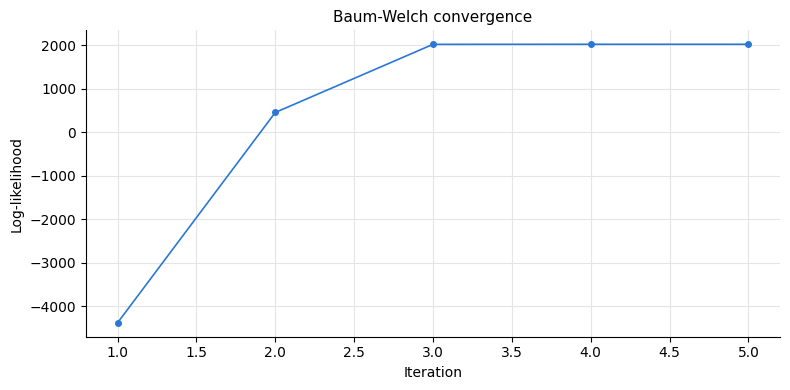

In [37]:
convergence_figure, convergence_plot = plt.subplots(figsize=(8, 4))

convergence_plot.plot(range(1, iterations_used + 1), log_likelihood_history, color=ACTIVITY_COLORS["still"], marker="o", markersize=4)

convergence_plot.set_xlabel("Iteration")

convergence_plot.set_ylabel("Log-likelihood")

convergence_plot.set_title("Baum-Welch convergence")

convergence_figure.tight_layout()

convergence_figure.savefig(os.path.join(FIGURES_FOLDER, "baum_welch_convergence.png"), dpi=FIGURE_DPI)

plt.show()

A quick sanity check before touching the test data: decode the training sequence itself. This is **not** the evaluation (the model has seen this data), it only confirms that the states still line up with the activities after training.

In [38]:
training_path = run_viterbi(training_observations, trained_model)

training_accuracy = (training_path == training_states).mean()

print(f"Training accuracy (sanity check only): {training_accuracy:.3f}")

Training accuracy (sanity check only): 1.000


## 9. Visualising the Trained Model

### Transition probabilities (A)

In [39]:
def plot_matrix(matrix: np.ndarray, row_labels: list[str], column_labels: list[str], title: str, value_format: str, axis_plot: Axes) -> None:
    image = axis_plot.imshow(matrix, cmap=SEQUENTIAL_COLOR_MAP)

    add_matrix_labels(matrix, row_labels, column_labels, title, value_format, axis_plot)

    plt.colorbar(image, ax=axis_plot)


def add_matrix_labels(matrix: np.ndarray, row_labels: list[str], column_labels: list[str], title: str, value_format: str, axis_plot: Axes) -> None:
    axis_plot.set_xticks(range(len(column_labels)))

    axis_plot.set_xticklabels(column_labels, rotation=30)

    axis_plot.set_yticks(range(len(row_labels)))

    axis_plot.set_yticklabels(row_labels)

    axis_plot.grid(False)

    axis_plot.set_title(title)

    for row in range(matrix.shape[0]):
        for column in range(matrix.shape[1]):
            value = matrix[row, column]

            value_text = format(value, value_format)

            axis_plot.text(column, row, value_text, ha="center", va="center", bbox=HEATMAP_LABEL_BOX)

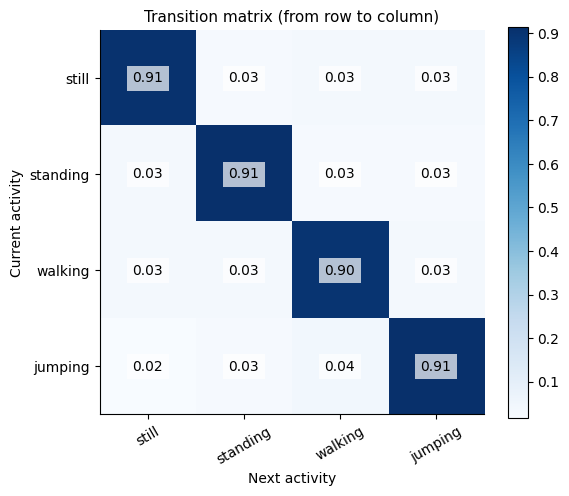

In [40]:
transition_figure, transition_plot = plt.subplots(figsize=(6, 5))

plot_matrix(trained_model["transition_matrix"], ACTIVITIES, ACTIVITIES, "Transition matrix (from row to column)", ".2f", transition_plot)

transition_plot.set_xlabel("Next activity")

transition_plot.set_ylabel("Current activity")

transition_figure.tight_layout()

transition_figure.savefig(os.path.join(FIGURES_FOLDER, "transition_matrix.png"), dpi=FIGURE_DPI)

plt.show()

### Emission probabilities (B)

Each activity's emission is a set of bell curves, one per feature. The heatmap shows the **mean** of every bell curve (in z-score units). The curves below show the full bell curves for the two features that matter most for the hardest pair, still vs standing.

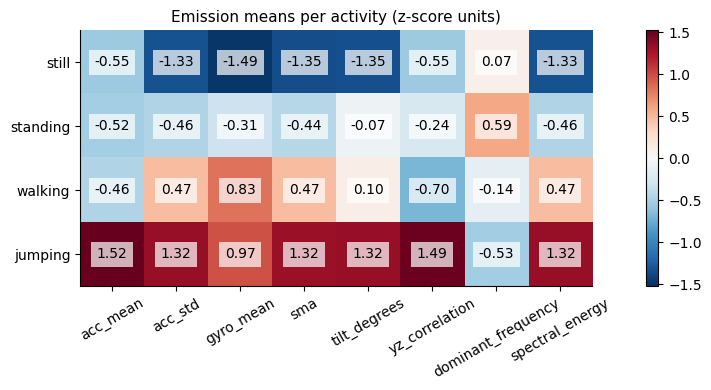

In [41]:
emission_means = trained_model["means"]

color_limit = np.abs(emission_means).max()

emission_figure, emission_plot = plt.subplots(figsize=(11, 4))

emission_image = emission_plot.imshow(emission_means, cmap=DIVERGING_COLOR_MAP, vmin=-color_limit, vmax=color_limit)

add_matrix_labels(emission_means, ACTIVITIES, FEATURE_NAMES, "Emission means per activity (z-score units)", ".2f", emission_plot)

plt.colorbar(emission_image, ax=emission_plot)

emission_figure.tight_layout()

emission_figure.savefig(os.path.join(FIGURES_FOLDER, "emission_means.png"), dpi=FIGURE_DPI)

plt.show()

In [42]:
def calculate_gaussian_curve(x_values: np.ndarray, mean: float, variance: float) -> np.ndarray:
    normaliser = np.sqrt(2 * np.pi * variance)

    exponent = -((x_values - mean) ** 2) / (2 * variance)

    return np.exp(exponent) / normaliser


def plot_emission_curves(feature_name: str, model: HmmModel, axis_plot: Axes) -> None:
    feature_index = FEATURE_NAMES.index(feature_name)

    x_values = np.linspace(CURVE_X_MIN, CURVE_X_MAX, CURVE_POINTS)

    for state, activity in enumerate(ACTIVITIES):
        mean = model["means"][state, feature_index]

        variance = model["variances"][state, feature_index]

        curve = calculate_gaussian_curve(x_values, mean, variance)

        axis_plot.plot(x_values, curve, color=ACTIVITY_COLORS[activity], label=activity, linewidth=2)

    axis_plot.set_title(f"Emission curves: {feature_name}")

    axis_plot.set_xlabel("Normalised value (z-score)")

    axis_plot.set_ylabel("Probability density")

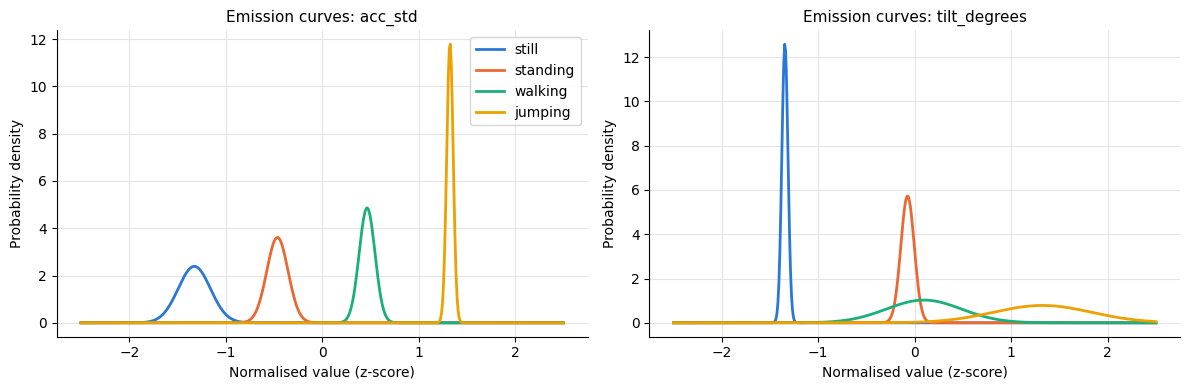

In [43]:
curves_figure, curve_axes = plt.subplots(1, len(EMISSION_CURVE_FEATURES), figsize=(12, 4))

for plot_number, feature_name in enumerate(EMISSION_CURVE_FEATURES):
    plot_emission_curves(feature_name, trained_model, curve_axes[plot_number])

curve_axes[0].legend()

curves_figure.tight_layout()

curves_figure.savefig(os.path.join(FIGURES_FOLDER, "emission_curves.png"), dpi=FIGURE_DPI)

plt.show()

## 10. Evaluation on Unseen Data

The three test sessions were recorded separately from the training data, in one continuous take each, with the activities in different orders and on different surfaces (see `data/test_labels.csv`). They were never used for training or for the normalisation statistics.

Each session is decoded with Viterbi from start to finish, transitions included. Only windows that sit fully inside a labelled block are scored.

In [44]:
decoded_sessions: dict[str, pd.DataFrame] = {}

for session_name in TEST_SESSIONS:
    session_table = test_normalised[session_name].copy()

    session_observations = session_table[FEATURE_NAMES].to_numpy()

    decoded_path = run_viterbi(session_observations, trained_model)

    session_table["predicted"] = convert_states_to_activities(decoded_path)

    decoded_sessions[session_name] = session_table

In [45]:
def plot_decoded_session(session_table: pd.DataFrame, session_name: str, axis_plot: Axes) -> None:
    scored_rows = session_table[session_table["activity"] != TRANSITION_LABEL]

    true_positions = [ACTIVITIES.index(activity) for activity in scored_rows["activity"]]

    predicted_positions = [ACTIVITIES.index(activity) for activity in session_table["predicted"]]

    axis_plot.scatter(scored_rows["start_time"], true_positions, color=TRUE_LABEL_COLOR, marker="s", s=TRUE_MARKER_SIZE, label="true activity")

    axis_plot.step(session_table["start_time"], predicted_positions, where="post", color=PREDICTED_LINE_COLOR, label="predicted (Viterbi)")

    axis_plot.set_yticks(range(len(ACTIVITIES)))

    axis_plot.set_yticklabels(ACTIVITIES)

    axis_plot.set_title(session_name)

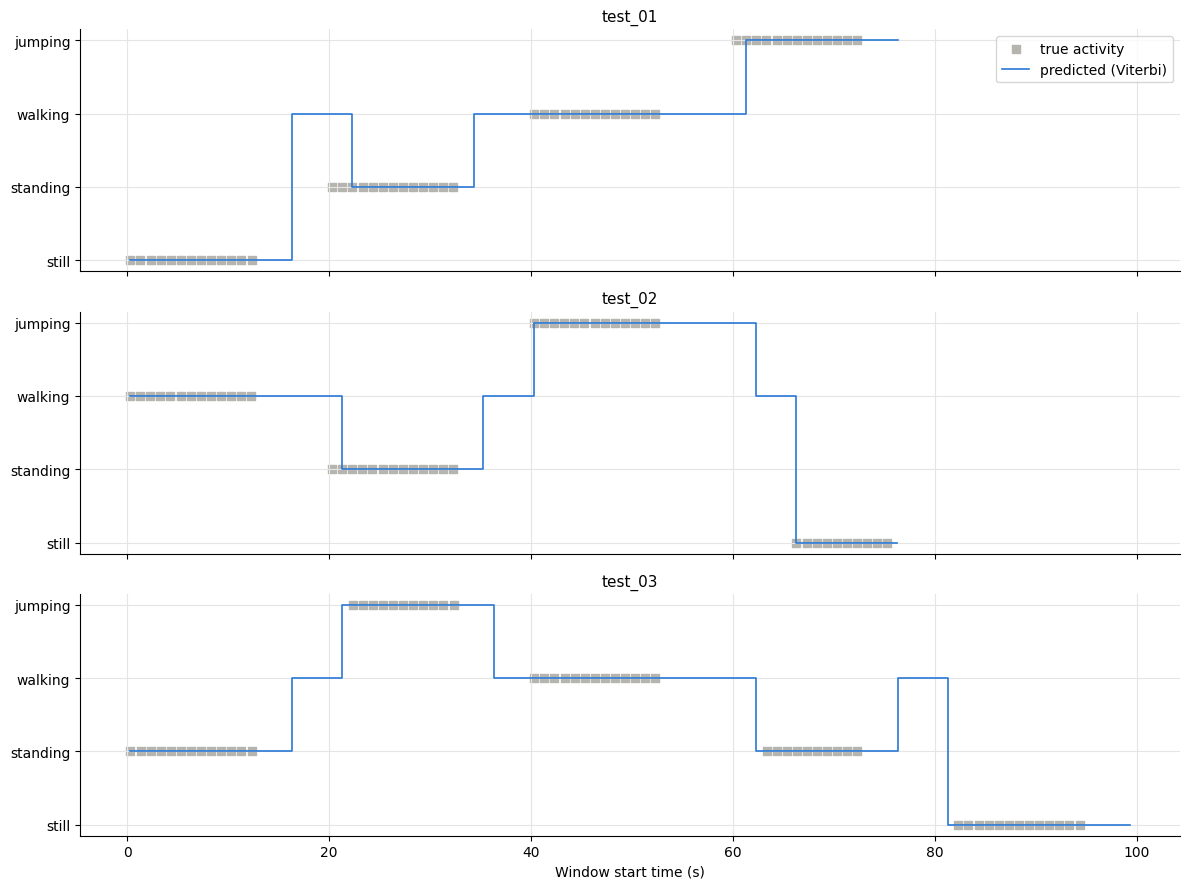

In [46]:
decoded_figure, decoded_axes = plt.subplots(len(TEST_SESSIONS), 1, figsize=(12, 9), sharex=True)

for row, session_name in enumerate(TEST_SESSIONS):
    plot_decoded_session(decoded_sessions[session_name], session_name, decoded_axes[row])

decoded_axes[0].legend(loc="upper right")

decoded_axes[-1].set_xlabel("Window start time (s)")

decoded_figure.tight_layout()

decoded_figure.savefig(os.path.join(FIGURES_FOLDER, "decoded_sequences.png"), dpi=FIGURE_DPI)

plt.show()

### Metrics

For each activity, treated as "this activity vs everything else":

- **Sensitivity** = TP / (TP + FN): of the windows that really were this activity, how many did the model catch?
- **Specificity** = TN / (TN + FP): of the windows that were *not* this activity, how many did the model correctly leave alone?
- **Accuracy** = (TP + TN) / all scored windows

In [47]:
def collect_scored_windows(sessions: dict[str, pd.DataFrame]) -> pd.DataFrame:
    scored_tables: list[pd.DataFrame] = []

    for session_name, session_table in sessions.items():
        scored_rows = session_table[session_table["activity"] != TRANSITION_LABEL].copy()

        scored_rows["session"] = session_name

        scored_tables.append(scored_rows)

    return pd.concat(scored_tables, ignore_index=True)


def build_confusion_matrix(true_activities: pd.Series, predicted_activities: pd.Series) -> np.ndarray:
    confusion = np.zeros((STATE_COUNT, STATE_COUNT), dtype=int)

    for true_activity, predicted_activity in zip(true_activities, predicted_activities):
        true_index = ACTIVITIES.index(true_activity)

        predicted_index = ACTIVITIES.index(predicted_activity)

        confusion[true_index, predicted_index] = confusion[true_index, predicted_index] + 1

    return confusion


def calculate_activity_metrics(confusion: np.ndarray, activity_index: int) -> ActivityMetrics:
    total = confusion.sum()

    true_positives = confusion[activity_index, activity_index]

    false_negatives = confusion[activity_index, :].sum() - true_positives

    false_positives = confusion[:, activity_index].sum() - true_positives

    true_negatives = total - true_positives - false_negatives - false_positives

    metrics: ActivityMetrics = {
        "activity": ACTIVITIES[activity_index],
        "samples": int(true_positives + false_negatives),
        "sensitivity": round(float(true_positives / (true_positives + false_negatives)), 3),
        "specificity": round(float(true_negatives / (true_negatives + false_positives)), 3),
        "accuracy": round(float((true_positives + true_negatives) / total), 3),
    }

    return metrics

In [48]:
scored_windows = collect_scored_windows(decoded_sessions)

confusion = build_confusion_matrix(scored_windows["activity"], scored_windows["predicted"])

metrics_rows: list[ActivityMetrics] = []

for activity_index in range(STATE_COUNT):
    metrics_rows.append(calculate_activity_metrics(confusion, activity_index))

metrics_table = pd.DataFrame(metrics_rows)

overall_accuracy = np.trace(confusion) / confusion.sum()

print(f"Scored test windows: {confusion.sum()}")

print(f"Overall accuracy (all activities together): {overall_accuracy:.3f}")

metrics_table

Scored test windows: 161
Overall accuracy (all activities together): 0.975


,activity,samples,sensitivity,specificity,accuracy
0,still,36,1.000,1.000,1.000
1,standing,49,0.939,1.000,0.981
2,walking,39,1.000,0.967,0.975
3,jumping,37,0.973,1.000,0.994


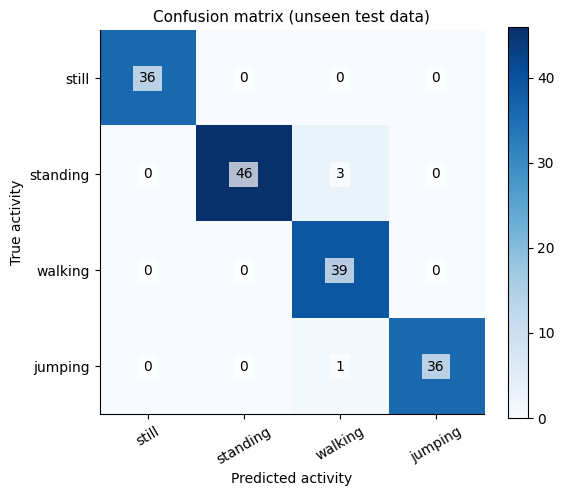

In [49]:
confusion_figure, confusion_plot = plt.subplots(figsize=(6, 5))

plot_matrix(confusion, ACTIVITIES, ACTIVITIES, "Confusion matrix (unseen test data)", "d", confusion_plot)

confusion_plot.set_xlabel("Predicted activity")

confusion_plot.set_ylabel("True activity")

confusion_figure.tight_layout()

confusion_figure.savefig(os.path.join(FIGURES_FOLDER, "confusion_matrix.png"), dpi=FIGURE_DPI)

plt.show()

In [50]:
session_rows: list[SessionAccuracy] = []

for session_name in TEST_SESSIONS:
    session_scored = scored_windows[scored_windows["session"] == session_name]

    correct_share = (session_scored["activity"] == session_scored["predicted"]).mean()

    session_row: SessionAccuracy = {"session": session_name, "accuracy": round(float(correct_share), 3)}

    session_rows.append(session_row)

pd.DataFrame(session_rows)

,session,accuracy
0,test_01,0.942
1,test_02,0.980
2,test_03,1.000


### What the results show

- **Overall accuracy on unseen data: 97.5% (157 of 161 scored windows).** Still was perfect in all three sessions, including test_03 where the phone lay on the carpet instead of the table.
- **All 4 mistakes sit in the very first window of a block, and all 4 were predicted as walking:**

| Session | Window start | True | Predicted | What really happened |
|---|---|---|---|---|
| test_01 | 20.3 s | standing | walking | I was still settling after picking the phone up from the table (the raw signal is still moving at 20 to 21 s) |
| test_01 | 21.3 s | standing | walking | Same settling period |
| test_01 | 60.3 s | jumping | walking | I was still walking until about 61 s, so this 2 s window is half walking, half jumping |
| test_02 | 20.3 s | standing | walking | I kept walking through the transition and only stopped at about 21 s |

  So the model was not confused between activities. My labels (taken from the timer) start a second or two before I had actually switched. The model followed what I was really doing.
- **Baum-Welch** climbed from a log-likelihood of -4377 to 2021 in 5 rounds and stopped by the convergence check, far below the 200 round limit. The transition matrix it learned matches the one counted from the labels exactly.
- **The transition matrix** has about 0.9 on the diagonal (an activity tends to continue) and about 0.03 everywhere else. The off-diagonal values are almost equal because the training clips were shuffled at random, so this model thinks jumping straight to still is as likely as standing to still. Real behaviour is not like that.